# Explore
Distribuciones, calidad y representatividad del corpus.

In [1]:
import json
import sys
from pathlib import Path

cwd = Path.cwd().resolve()
ROOT = next(folder for folder in (cwd, *cwd.parents)
            if (folder / "data" / "dataset.csv").is_file()
            and (folder / "scripts" / "corpus.py").is_file())
sys.path.insert(0, str(ROOT))

if "show_chart" not in globals():
    def show_chart(name):
        from IPython.display import SVG, display
        display(SVG(filename=str(ROOT / "artifacts" / "charts" / f"{name}.svg")))


In [2]:
from scripts import corpus
rows = corpus.read()
summary = corpus.describe(rows)
print(json.dumps(summary, ensure_ascii=False, indent=2))
clean = corpus.normalize(rows)
print("Filas con etiquetas inconsistentes o rechazadas:", len(rows) - len(clean))

{
  "registros": 800,
  "proyectos": 20,
  "familias": 60,
  "duplicados_exactos": 0,
  "faltantes_requeridos": 0,
  "particiones": {
    "train": 560,
    "validation": 120,
    "test": 120
  },
  "lenguajes_formatos": {
    "Python": 200,
    "JavaScript": 200,
    "YAML": 200,
    "Properties": 200
  },
  "clases": {
    "no vulnerable": 400,
    "vulnerable": 400
  },
  "categorias": {
    "A01:2025": 80,
    "A02:2025": 80,
    "A04:2025": 80,
    "A06:2025": 80,
    "A07:2025": 80,
    "API1:2023": 71,
    "API2:2023": 71,
    "API4:2023": 71,
    "API8:2023": 71
  },
  "longitud_caracteres": {
    "min": 19,
    "promedio": 33.76,
    "max": 49
  }
}
Filas con etiquetas inconsistentes o rechazadas: 0


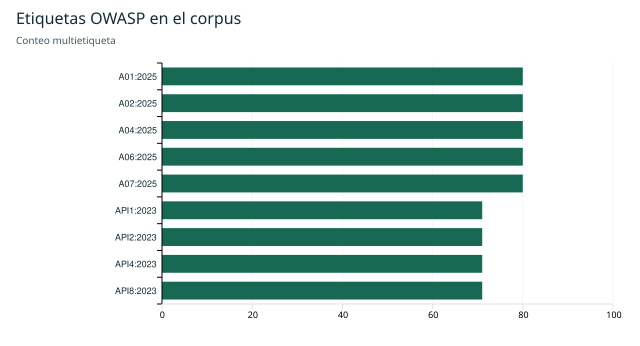

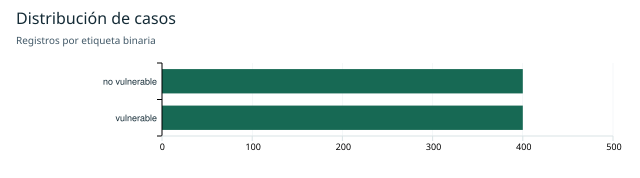

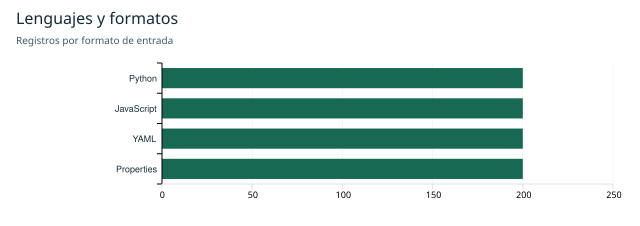

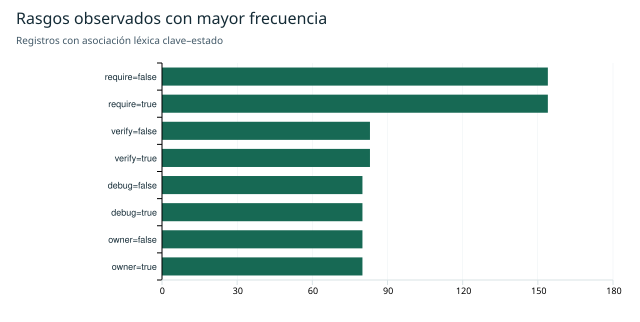

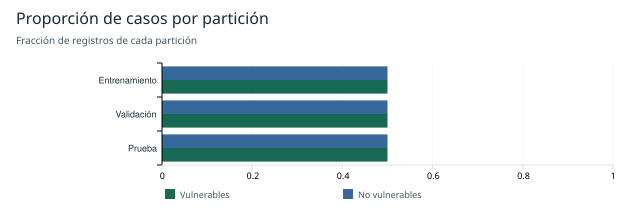

In [3]:
for name in ("categorias", "clases", "lenguajes", "rasgos", "desbalance"):
    show_chart(name)

La clase binaria está balanceada en las tres particiones. Las categorías de API tienen menor soporte porque requieren contexto. Las frecuencias se refieren a registros, que pueden contribuir a dos categorías OWASP. Los ejemplos se concentran en configuraciones o declaraciones cortas y en cuatro formatos. La repetición semántica entre plantillas limita la diversidad del corpus.